# 05 · StreetCLIP fine-tuning — setup and checks (Louis)

Before we spend GPU hours on the cluster, this notebook checks, step by step, that everything the
fine-tuning needs is right. Each section answers one question:

| | Question | Why it matters |
|---|---|---|
| a | Is the software right? | `peft` (LoRA) and a recent `transformers` are needed; we want to know which device we train on |
| b | Is the data right? | every image of `splits.csv` must exist, otherwise a job crashes after an hour |
| c | Is the pre-processing right? | team rules: UI cropped, **no horizontal flip**, colour jitter without hue; the evaluation view must be *exactly* Thea's |
| d | Are the existing prediction files valid? | the comparison with zero-shot and the probe uses them |
| e | Does our model reproduce Thea's zero-shot *before* training? (optional, real model) | if epoch 0 is not her zero-shot, any gain we report could be a pipeline difference, not learning |
| f | Do training, checkpoints and `--resume` work? (optional, tiny run) | the cluster cuts jobs at the time limit: resume is our safety net |
| g | Are we ready for the cluster? | a checklist |

Runs on a laptop (CPU / Apple MPS) **and** on the cluster. Sections e and f are switched off by default
(`RUN_REAL_MODEL = False`, `RUN_SMOKE = False`) because they download StreetCLIP (1.7 GB) and need a few
minutes of GPU; switch them on deliberately. The cluster steps themselves are in `docs/cluster.md`.

In [1]:
import os, sys, time, tempfile
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
%config InlineBackend.figure_format = "jpeg"   # photos: much smaller notebook than PNG

from geosense import crop_ui, load_classes, load_manifest
from geosense.data import PROJECT_ROOT
from geosense.preprocess import CLIP_MEAN, CLIP_STD, ViewDataset, find_dataset_root
from geosense.predictions import PRED_DIR, check_val

# --- switches --------------------------------------------------------------------------------
RUN_REAL_MODEL = False   # (e) load StreetCLIP and compare epoch 0 with Thea's zero-shot (1.7 GB download)
RUN_SMOKE = False        # (f) tiny fine-tuning run + --resume (uses StreetCLIP too)
N_COMPARE = 256          # (e) number of validation images compared
SMOKE_EXTRA = []         # (f) extra geosense.finetune options, e.g. ["--device", "cpu"] if MPS fails
# --- dataset folder: $GEOSENSE_DATA (cluster.env) or the usual laptop locations ---------------
DATA_ROOT = Path(os.environ.get("GEOSENSE_DATA") or
                 find_dataset_root(extra=[Path("~/Downloads/geosense_dataset/compressed_dataset").expanduser()]))
print("dataset:", DATA_ROOT)
checks = {}              # filled by every section, summarised in (g)

dataset: ~/Downloads/geosense_dataset/compressed_dataset


## a. Environment

Versions of the libraries and the device the code will use (`cuda` on the cluster, `mps` on an Apple
laptop, else `cpu`). `peft` must import: it provides the LoRA adapters (`--method lora`).

In [2]:
import torch, torchvision, transformers

print("python      ", sys.version.split()[0])
print("torch       ", torch.__version__, "| CUDA build:", torch.version.cuda)
print("torchvision ", torchvision.__version__)
print("transformers", transformers.__version__)
try:
    import peft
    print("peft        ", peft.__version__)
    peft_ok = True
except ImportError as e:
    print("peft         MISSING:", e, "-> pip install peft")
    peft_ok = False

if torch.cuda.is_available():
    device = "cuda"
    p = torch.cuda.get_device_properties(0)
    print(f"device       cuda: {p.name}, {p.total_memory / 2**30:.1f} GB")
elif torch.backends.mps.is_available():
    device = "mps"
    print("device       mps (Apple GPU) - fine for checks, too slow for the real training")
else:
    device = "cpu"
    print("device       cpu - fine for checks, not for training")

try:
    import geosense.finetune as ft
    finetune_ok = True
    print("geosense.finetune importable:", ft.__file__)
except ImportError as e:
    ft, finetune_ok = None, False
    print("geosense.finetune NOT importable yet:", e)
checks["environment (peft + geosense.finetune)"] = peft_ok and finetune_ok

python       3.11.18
torch        2.15.0 | CUDA build: None
torchvision  0.29.2
transformers 5.24.1


W1126 21:40:20.488000 53384 site-packages/torch/distributed/elastic/multiprocessing/redirects.py:35] NOTE: Redirects are currently not supported in MacOs.


peft         0.22.0
device       mps (Apple GPU) - fine for checks, too slow for the real training


geosense.finetune importable: <repo>/src/geosense/finetune.py


## b. Data

The team contract: `data/splits.csv` lists every kept image (path relative to `compressed_dataset/`) and its
split; `data/classes.json` gives the 56 countries (index = class id). We check that **every** path exists on
this machine and that the split sizes are the agreed ones (70 / 15 / 15, seed 42, never re-split).

In [3]:
manifest = load_manifest()
classes, _ = load_classes()
missing = [p for p in manifest.path if not (DATA_ROOT / p).is_file()]
sizes = manifest.split.value_counts().reindex(["train", "val", "test"])
print(f"{len(manifest):,} images in splits.csv, missing on disk: {len(missing)}", missing[:3])
print("split sizes:", sizes.to_dict())
print("classes:", len(classes), "| every country of splits.csv is a class:", set(manifest.country) <= set(classes))

data_ok = (not missing and len(classes) == 56 and manifest.label.notna().all()
           and sizes.to_dict() == {"train": 33464, "val": 7171, "test": 7172})
checks["data (all images found, 56 classes, split sizes)"] = data_ok
print("OK" if data_ok else "PROBLEM: see above")

47,807 images in splits.csv, missing on disk: 0 []
split sizes: {'train': 33464, 'val': 7171, 'test': 7172}
classes: 56 | every country of splits.csv is a class: True
OK


## c. Pre-processing

What the model sees. One validation image: the raw screenshot, after the UI crop (`crop_ui`: compass and
buttons on the left, score box and mini-map on the right), the **evaluation view** (resize the short side to
336 px, centre crop — Thea's view) and four draws of the **training augmentation** (slightly larger resize,
random 336 crop, colour jitter on brightness / contrast / saturation, *no hue*). There is **no horizontal
flip**: the driving side and the direction of the text are clues for the country, a flip would teach the
model wrong ones. We also check numerically that our evaluation transform gives exactly the same tensor as
Thea's `ViewDataset`, so that the un-trained model must reproduce her zero-shot.

train transforms: Resize -> RandomCrop -> ColorJitter -> ToTensor -> Normalize
no flip: True | colour jitter without hue: True | eval view vs Thea's ViewDataset, max abs diff: 0.0


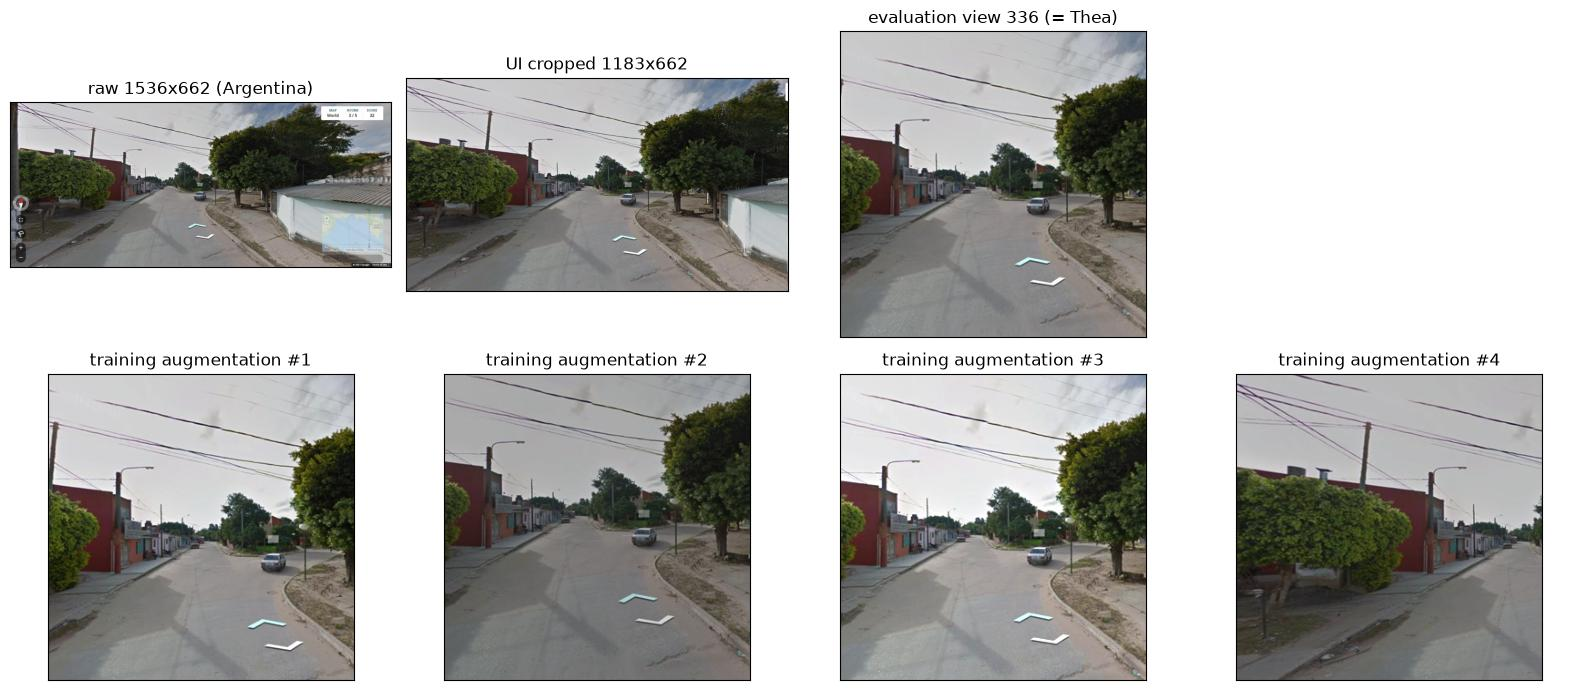

In [4]:
val = manifest[manifest.split == "val"].reset_index(drop=True)
row = val.iloc[0]
raw = Image.open(DATA_ROOT / row.path).convert("RGB")
cropped = crop_ui(raw)

def show(t):
    # undo the CLIP normalisation to display a tensor
    a = t.numpy().transpose(1, 2, 0) * np.array(CLIP_STD) + np.array(CLIP_MEAN)
    return np.clip(a, 0, 1)

prep_ok = False
if ft is None:
    print("geosense.finetune not available: section skipped")
else:
    eval_tf, train_tf = ft.build_transforms(False, 336, "centre"), ft.build_transforms(True, 336)
    names = [type(t).__name__ for t in train_tf.transforms]
    jitter = [t for t in train_tf.transforms if type(t).__name__ == "ColorJitter"]
    no_flip = not any("Flip" in n for n in names)
    no_hue = bool(jitter) and jitter[0].hue is None
    thea = ViewDataset(DATA_ROOT, [row.path], 336, "centre")[0][0]
    same_as_thea = float((eval_tf(cropped) - thea).abs().max())
    print("train transforms:", " -> ".join(names))
    print("no flip:", no_flip, "| colour jitter without hue:", no_hue,
          "| eval view vs Thea's ViewDataset, max abs diff:", same_as_thea)

    fig, ax = plt.subplots(2, 4, figsize=(16, 7))
    ax[0, 0].imshow(raw); ax[0, 0].set_title(f"raw {raw.size[0]}x{raw.size[1]} ({row.country})")
    ax[0, 1].imshow(cropped); ax[0, 1].set_title(f"UI cropped {cropped.size[0]}x{cropped.size[1]}")
    ax[0, 2].imshow(show(eval_tf(cropped))); ax[0, 2].set_title("evaluation view 336 (= Thea)")
    ax[0, 3].axis("off")
    torch.manual_seed(0)
    for i in range(4):
        ax[1, i].imshow(show(train_tf(cropped))); ax[1, i].set_title(f"training augmentation #{i + 1}")
    for a in ax.flat:
        a.set_xticks([]); a.set_yticks([])
    plt.tight_layout(); plt.show()
    prep_ok = no_flip and no_hue and same_as_thea < 1e-5
checks["pre-processing (no flip, no hue, eval view = Thea)"] = prep_ok

## d. Prediction files already in `predictions/`

`check_val()` reads every exported model of the team contract and prints its **validation** scores
(it never looks at test labels). These are the numbers fine-tuning has to beat: zero-shot and the probe.

In [5]:
check_val()
zs_file = PRED_DIR / "streetclip_zeroshot_val_logits.npy"
zs = np.load(zs_file) if zs_file.exists() else None
contract_ok = zs is not None and zs.shape == (len(val), len(classes)) and zs.dtype == np.float32
checks["contract files (zero-shot val logits present, right shape)"] = contract_ok
print("zero-shot val logits:", None if zs is None else (zs.shape, zs.dtype))

model                      top-1   top-5  macro-F1
majority                   0.250   0.505     0.007
histogram_lr               0.110   0.359     0.092
histogram_rf               0.232   0.560     0.119
streetclip_zeroshot        0.820   0.974     0.695
streetclip_probe           0.885   0.987     0.776
zero-shot val logits: ((7171, 56), dtype('float32'))


## e. (optional) Epoch 0 = Thea's zero-shot?

Our fine-tuning model starts from the zero-shot model: its classifier head is initialised with the text
embeddings of the country prompts, so *before any training* it should give the same logits as Thea's
`streetclip_zeroshot_val_logits.npy`. We load StreetCLIP, build our model (`StreetCLIPClassifier`), run it on
the first validation images with our evaluation transform, and compare with the same rows of her file.

We do not know which square view (`centre` / `squash`) and which prompt set (`TEMPLATE_SETS`) Thea chose on
validation, so we try all combinations and report the one that matches. Thea stored her embeddings in float16
and ran on a GPU in half precision, so small differences (a few hundredths of a logit) are expected; a wrong
view or prompt set gives differences of whole logits and many changed predictions. Use the matching
combination as `--view-mode` / `--templates` for every run (defaults: `centre`, `street_view`).

In [6]:
match = None
if not RUN_REAL_MODEL:
    print("skipped (RUN_REAL_MODEL = False)")
elif ft is None or zs is None:
    print("skipped: geosense.finetune or the zero-shot file is missing")
else:
    import torch.nn.functional as F
    from torch.utils.data import DataLoader, Subset
    from geosense import GeoSenseDataset
    from geosense.streetclip import TEMPLATE_SETS, load_streetclip, text_weights

    dev = ft.get_device("auto")
    clip, tok = load_streetclip()                      # 1.7 GB download the first time
    scale = clip.logit_scale.exp().item()
    W = {k: text_weights(clip, tok, classes, t, str(dev)) for k, t in TEMPLATE_SETS.items()}
    model = ft.StreetCLIPClassifier(clip.cpu(), W["street_view"], scale).to(dev).eval()
    rows = []
    for view_mode in ("centre", "squash"):
        ds = Subset(GeoSenseDataset(DATA_ROOT, "val", ft.build_transforms(False, model.image_size, view_mode)),
                    range(N_COMPARE))
        loader = DataLoader(ds, batch_size=32, shuffle=False, num_workers=0)
        logits, y = ft.predict_logits(model, loader, dev)            # the real forward pass (street_view head)
        with torch.no_grad():                                        # same embeddings, other heads
            Z = torch.cat([model.embed(x.to(dev)).float().cpu() for x, _ in loader])
        for key, Wk in W.items():
            lk = logits if key == "street_view" else (scale * F.normalize(Z, dim=-1) @ F.normalize(torch.from_numpy(Wk), dim=-1).T).numpy()
            ref = zs[:N_COMPARE]
            rows.append({"view_mode": view_mode, "templates": key, "max_abs_diff": float(np.abs(lk - ref).max()),
                         "argmax_agreement": float((lk.argmax(1) == ref.argmax(1)).mean())})
    table = pd.DataFrame(rows).sort_values("max_abs_diff").reset_index(drop=True)
    display(table)
    match = table.iloc[0].to_dict()
    print(f"best match: --view-mode {match['view_mode']} --templates {match['templates']} "
          f"(max abs diff {match['max_abs_diff']:.3f}, argmax agreement {match['argmax_agreement']:.1%})")
    del clip, model
checks["epoch 0 reproduces Thea's zero-shot (optional)"] = (
    None if match is None else match["argmax_agreement"] >= 0.99 and match["max_abs_diff"] < 0.5)

skipped (RUN_REAL_MODEL = False)


## f. (optional) A tiny fine-tuning run, then `--resume`

The same thing as the cluster smoke job (`scripts/slurm/smoke.sbatch`), but from Python and very small:
64 training images, one epoch, only the last vision block trained. Then we call it again with `--epochs 2
--resume`: it must say `resumed after epoch 1` and train only epoch 2. The history must contain epochs
0 (the zero-shot reference, before any update), 1 and 2. Checkpoints go to a temporary folder; the history /
config files written to `results/` are deleted afterwards so they are never committed by mistake.

In [7]:
smoke_ok = None
if not RUN_SMOKE:
    print("skipped (RUN_SMOKE = False)")
elif ft is None:
    print("skipped: geosense.finetune is missing")
else:
    ckpt_dir = Path(tempfile.mkdtemp(prefix="geosense_ckpt_"))
    args = ["--root", str(DATA_ROOT), "--run-name", "nb05_smoke", "--subset", "64", "--method", "last_blocks",
            "--unfreeze-blocks", "1", "--batch-size", "8", "--workers", "0", "--ckpt-dir", str(ckpt_dir), *SMOKE_EXTRA]
    t0 = time.time(); ft.main(args + ["--epochs", "1"]); print(f"pass 1: {time.time() - t0:.0f} s")
    t0 = time.time(); ft.main(args + ["--epochs", "2", "--resume"]); print(f"pass 2: {time.time() - t0:.0f} s")
    # subset runs add "_subset64" to the file / folder names: glob instead of guessing
    hist_file = sorted((PROJECT_ROOT / "results").glob("nb05_smoke*_history.csv"))[0]
    hist = pd.read_csv(hist_file)
    display(hist)
    ckpts = sorted(ckpt_dir.glob("nb05_smoke*/*.pt"))
    print("checkpoints:", [f"{p.parent.name}/{p.name}" for p in ckpts])
    smoke_ok = hist.epoch.tolist() == [0, 1, 2] and any(p.name == "last.pt" for p in ckpts)
    for f in (PROJECT_ROOT / "results").glob("nb05_smoke*"):
        f.unlink()
checks["tiny fine-tune + resume (optional)"] = smoke_ok

skipped (RUN_SMOKE = False)


## g. Ready for the cluster when…

Green here means the code and the data are right on *this* machine. The cluster has its own checklist
(`docs/cluster.md`): `cluster.env` filled from `00_inspect_cluster.sh`, `setup_env.sh` and `fetch_assets.sh`
passed, and the **smoke job passed on the cluster** — only then submit the real runs.

In [8]:
for name, ok in checks.items():
    print(f"{'PASS' if ok else ('not run' if ok is None else 'FAIL'):>8}  {name}")
print()
print("On the cluster (docs/cluster.md):")
for step in ["00_inspect_cluster.sh output sent to the team", "cluster.env filled (DRY_RUN=1 submit.sh --smoke looks right)",
             "setup_env.sh: OK", "fetch_assets.sh: 49,997 JPEGs, 0 missing, StreetCLIP available offline",
             "submit.sh --smoke: SMOKE TEST PASSED, time + GPU memory written in docs/cluster.md",
             "section e run once (here or on the cluster): --view-mode / --templates that match Thea"]:
    print("  [ ]", step)
required = [v for k, v in checks.items() if "optional" not in k]
print("\nREADY for the cluster smoke test" if all(required) else "\nNOT READY: fix the FAIL lines first")

    PASS  environment (peft + geosense.finetune)
    PASS  data (all images found, 56 classes, split sizes)
    PASS  pre-processing (no flip, no hue, eval view = Thea)
    PASS  contract files (zero-shot val logits present, right shape)
 not run  epoch 0 reproduces Thea's zero-shot (optional)
 not run  tiny fine-tune + resume (optional)

On the cluster (docs/cluster.md):
  [ ] 00_inspect_cluster.sh output sent to the team
  [ ] cluster.env filled (DRY_RUN=1 submit.sh --smoke looks right)
  [ ] setup_env.sh: OK
  [ ] fetch_assets.sh: 49,997 JPEGs, 0 missing, StreetCLIP available offline
  [ ] submit.sh --smoke: SMOKE TEST PASSED, time + GPU memory written in docs/cluster.md
  [ ] section e run once (here or on the cluster): --view-mode / --templates that match Thea

READY for the cluster smoke test
